# Round 2 pricing simulator (Lender 3)

Chooses the Round 2 pricing rule and writes the submission file.

## Summary

**Decision: C single, `rate = p/(1−p) + 2% + 1.5·p`** (break-even plus a margin that grows with risk; no offer if the rate would exceed 100%). File: `data/processed/stage2_offers_lender3.csv`.

**Why**
- In Round 1 we used `b = 0.75`: our margins were too thin (see `round1_diagnostic.ipynb`). Raising the margin is clearly right, but **how much** depends on how rivals react.
- We test every rule in two ways (section 1): **View 1** replays the real Round 1 offers (*what if the market stays like Round 1?*); **View 2** simulates rivals pricing from their own models (*what if rivals learn?*).
- **C single is the only rule that does well in both**: View 1 average 43.7 M€ (vs 30.1 for the Round 1 rule) and View 2 average 41.2 M€ (the best). In the most realistic scenario, a **mixed market** where some rival teams keep their Round 1 behaviour and some learn, it earns 51.1 M€, the most of all rules.
- **C by bucket and best response** earn much more if the market stays exactly like Round 1 (up to 110 M€), because they exploit the gaps rivals left (refusals, very high quotes): best response charges ~80% to almost everyone. When rivals learn they drop to 1–19 M€. That is a bet that rivals will not change, so we did not take it.
- Expected Round 2 profit: roughly **30–65 M€** depending on rivals; worst case tested 7.5 M€ (all rivals move to a moderate margin and undercut us). No rule loses money in any scenario.

**Notebook map:** 1. two views explained · 2–3. markets and rival scenarios · 4. candidate rules · 5. results (decision table, upside vs robustness chart) · 6. Round 2 file.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 42
RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")
COLORS = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]  # Okabe-Ito, colorblind-safe

LOAN = 10_000
BONUS = 0.02
N_APPLICANTS = 100_000
pd.set_option("display.width", 220)


def break_even(p):
    """Rate with zero expected profit: r·(1 − p) = p."""
    return p / (1 - p)


def finalize(rate, prob):
    """Never below break-even; no offer above the 100% cap."""
    rate = np.maximum(rate, break_even(prob))
    return np.where(rate > 1, np.nan, rate)

## 1. Two ways to test a pricing rule

A rule's profit depends on what the **rivals** offer, which we cannot know in advance. We test every rule in two complementary ways:

| | **View 1: replay the real Round 1 market** | **View 2: simulate rivals with a strategy** |
|---|---|---|
| **Borrowers** | The 100,000 Round 1 applicants (diagnostic file) | The 30,000 past loans of the shared test split |
| **Rival offers** | The **actual offers** rivals made in Round 1, then adjusted (cheaper, dearer, fewer refusals) | **Simulated**: each rival prices from its own signal model's PD with a pricing rule |
| **Question it answers** | *If the Round 2 market looks like Round 1, how much do we make?* | *If rivals learn and price sensibly, how much do we make?* |
| **Strength** | Real behaviour, including the "gaps" rivals left (refusals, very high quotes on risky borrowers) | Rivals use their private information and serve everyone at sensible prices |
| **Blind spot** | Every scenario keeps Round 1's structure: rules that exploit Round 1's gaps look better than they are | The rival rules are our assumptions |

A rule worth submitting must do well in **both**.

Both views use the same market rules (lowest rate wins after a 2% bonus for the borrower's preferred lender; each preference type is ⅓ of borrowers) and the same profit per loan: `+rate × 10,000 €` if repaid, `−10,000 €` if default.

## 2. View 1 market: Round 1 replay

- `p`: our PD for Round 1 applicants from the **Stage 1 model**, which never saw their outcomes (out-of-sample).
- `C1`, `C2`: offers of the Lender 1 and Lender 2 teams we faced on each loan (`NaN` = no offer). `D`: actual default.

The replay engine must reproduce our actual Round 1 profit exactly when fed our Round 1 offers and the realized borrower types.

In [2]:
diag = pd.read_csv(RAW_DIR / "Round1_Diagnostic_33.csv")
pd_r1 = pd.read_csv(PROCESSED_DIR / "signal3_new_applications_predictions_catboost.csv")[["id", "pd"]]
r1 = diag.merge(pd_r1, on="id", how="left", validate="one_to_one")
assert len(r1) == N_APPLICANTS and r1["pd"].notna().all()
p, D = r1["pd"].to_numpy(), r1["default"].to_numpy()
C1, C2 = r1["competing1"].to_numpy(), r1["competing2"].to_numpy()


def win_share(rate, c1, c2, types=None):
    """Share of the loan we win (0, 1/3, 2/3 or 1), averaged over the 3 preference types; NaN = no offer."""
    ours = np.where(np.isnan(rate), np.inf, rate)
    a, b = np.where(np.isnan(c1), np.inf, c1), np.where(np.isnan(c2), np.inf, c2)
    wins_if = [ours < np.minimum(a - BONUS, b),      # borrower prefers Lender 1
               ours < np.minimum(a, b - BONUS),      # prefers Lender 2
               ours - BONUS < np.minimum(a, b)]      # prefers us
    if types is not None:
        return np.select([types == 1, types == 2, types == 3], wins_if).astype(float)
    return sum(w.astype(float) for w in wins_if) / 3


def loan_profit(rate, c1, c2, d, types=None):
    """Our expected profit on each loan (€)."""
    return win_share(rate, c1, c2, types) * LOAN * (np.nan_to_num(rate) * (1 - d) - d)


replayed = loan_profit(r1["own"].to_numpy(), C1, C2, D, types=r1["borrowertype"].to_numpy()).sum()
assert np.isclose(replayed, r1["profit"].sum()), "replay engine does not reproduce Round 1"
print(f"Engine check: replay {replayed:,.0f} € = actual Round 1 profit {r1['profit'].sum():,.0f} €")

Engine check: replay 30,908,296 € = actual Round 1 profit 30,908,296 €


### View 1 rival scenarios

Every team saw its results and its own diagnostic file. Plausible reactions, applied to the real Round 1 offers:

| Scenario | Why it is plausible | Change to Round 1 offers |
|---|---|---|
| **Same as Round 1** | Teams that did well keep their strategy | none |
| **Rivals 10% cheaper** | Teams that won few loans cut prices | rates × 0.90 |
| **Rivals 15% dearer** | Teams that earned little (LLMs, weak teams) learn their margins were too thin | rates × 1.15 (cap 100%) |
| **Rivals serve more** | Teams see refused applicants were profitable | half of each rival's refusals replaced by its median rate in that PD decile |
| **Tougher market** | Both at once | 10% cheaper + serve more |

Left out as unlikely after a round where every team made money: an all-out price war (25% cheaper), every refusal disappearing at once.

In [3]:
DECILE = pd.qcut(p, 10, labels=False)
rng = np.random.default_rng(SEED)


def decile_median(c):
    return pd.Series(c).groupby(DECILE).median().reindex(DECILE).to_numpy()


MED1, MED2 = decile_median(C1), decile_median(C2)
FILL1, FILL2 = rng.random(len(p)) < 0.5, rng.random(len(p)) < 0.5


def serve_more(c, med, fill):
    return np.where(np.isnan(c) & fill, med, c)


V1_SCENARIOS = {
    "Same as Round 1": (C1, C2),
    "Rivals 10% cheaper": (C1 * 0.90, C2 * 0.90),
    "Rivals 15% dearer": (np.minimum(C1 * 1.15, 1.0), np.minimum(C2 * 1.15, 1.0)),
    "Rivals serve more": (serve_more(C1, MED1, FILL1), serve_more(C2, MED2, FILL2)),
    "Tougher market": (serve_more(C1, MED1, FILL1) * 0.90, serve_more(C2, MED2, FILL2) * 0.90),
}
V1_NAMES = list(V1_SCENARIOS)

# Tuning and test halves: rules are tuned on one half of Round 1 and scored on the other
is_tune = np.random.default_rng(SEED + 1).random(len(p)) < 0.5
TUNE, TEST = np.flatnonzero(is_tune), np.flatnonzero(~is_tune)


def v1_profit(rate_all, rows, scenario):
    """Our View 1 profit on `rows`, scaled to 100k applicants (M€)."""
    c1, c2 = V1_SCENARIOS[scenario]
    return loan_profit(rate_all[rows], c1[rows], c2[rows], D[rows]).sum() * N_APPLICANTS / len(rows) / 1e6


def v1_scores(rate_all, rows):
    return {s: v1_profit(rate_all, rows, s) for s in V1_NAMES}


print(f"Tuning half: {len(TUNE):,} loans | test half: {len(TEST):,} loans")

Tuning half: 49,914 loans | test half: 50,086 loans


## 3. View 2 market: rivals with a strategy

Past loans of the test split, with out-of-sample PDs from the three signal models (`p1`, `p2`, `p3`) and the true default. Our rules price on `p3`; each rival prices on its own PD:

| Rival strategy | What it represents | Rival rate |
|---|---|---|
| **Round 1-like** | Rivals keep their Round 1 behaviour | break-even + the median markup rivals charged in Round 1 in that PD decile; refusals at the Round 1 rate of that decile |
| **Moderate learners** | Rivals raise margins a little | `p/(1−p) + 1% + 1·p` |
| **Learned rivals** | Rivals learned what we learned | `p/(1−p) + 2% + 2·p` |
| **Mixed market** | **Most realistic**: rivals are drawn per loan among 4 teams, some unchanged, some learned | each rival on each loan: Round 1-like or learned, 50/50 |

Left out as unlikely: rivals moving to *thinner* margins (break-even + 2%) after Round 1, and rivals copying our exact rule.

In [4]:
t30 = pd.read_csv(PROCESSED_DIR / "test.csv")[["id", "default", "signal3", "employment"]]
for k, file in [(1, "signal1_test_predictions_xgboost.csv"), (2, "signal2_test_predictions_spline.csv"),
                (3, "signal3_test_predictions_catboost.csv")]:
    t30 = t30.merge(pd.read_csv(PROCESSED_DIR / file)[["id", "pd"]].rename(columns={"pd": f"p{k}"}),
                    on="id", how="left", validate="one_to_one")
assert t30[["p1", "p2", "p3"]].notna().all().all()
P1, P2, P3, V2_D = (t30[c].to_numpy() for c in ["p1", "p2", "p3", "default"])

# "Round 1-like": markup over break-even and offer rate by PD decile, measured in the Round 1 diagnostic
dec_edges = np.quantile(p, np.linspace(0, 1, 11))
v2_rng = np.random.default_rng(SEED + 2)


def round1_like(prob, c_round1):
    cal = pd.DataFrame({"dec": DECILE, "markup": c_round1 - break_even(p), "offer": ~np.isnan(c_round1)}) \
            .groupby("dec").agg(markup=("markup", "median"), offer=("offer", "mean"))
    dec = np.clip(np.searchsorted(dec_edges, prob, side="right") - 1, 0, 9)
    rate = break_even(prob) + cal["markup"].to_numpy()[dec]
    refused = v2_rng.random(len(prob)) > cal["offer"].to_numpy()[dec]
    return np.where(refused | (rate > 1), np.nan, rate)


def c_rule(prob, a, b):
    return finalize(break_even(prob) + a + b * prob, prob)


R1_LIKE = (round1_like(P1, C1), round1_like(P2, C2))
LEARNED = (c_rule(P1, 0.02, 2.0), c_rule(P2, 0.02, 2.0))
MIX1, MIX2 = v2_rng.random(len(P1)) < 0.5, v2_rng.random(len(P2)) < 0.5
V2_SCENARIOS = {
    "Round 1-like": R1_LIKE,
    "Moderate learners": (c_rule(P1, 0.01, 1.0), c_rule(P2, 0.01, 1.0)),
    "Learned rivals": LEARNED,
    "Mixed market (50/50)": (np.where(MIX1, R1_LIKE[0], LEARNED[0]), np.where(MIX2, R1_LIKE[1], LEARNED[1])),
}
V2_NAMES = list(V2_SCENARIOS)


def v2_profit(rate_v2, scenario):
    """Our View 2 profit, scaled to 100k applicants (M€). `rate_v2` = our rates on the 30k test loans."""
    c1, c2 = V2_SCENARIOS[scenario]
    return loan_profit(rate_v2, c1, c2, V2_D).sum() * N_APPLICANTS / len(V2_D) / 1e6


print(f"View 2 market: {len(t30):,} past loans | default {V2_D.mean():.2%}")

View 2 market: 30,000 past loans | default 9.95%


## 4. Candidate rules

All rules start from break-even `p/(1−p)` and add a margin.

| Rule | Formula | How it is tuned |
|---|---|---|
| **Round 1 rule** (reference) | `p/(1−p) + 1% + 0.75·p` | what we submitted in Stage 1 |
| **C single** | `p/(1−p) + a + b·p` | `a`, `b` chosen to do well in **both views**: average of View 1 (tuning half) and View 2 |
| **C by bucket** | `p/(1−p) + b(p)·p`, one `b` per PD quartile, interpolated | 4 values of `b` (max 5), View 1 tuning half |
| **Best response** | for each PD level, the rate that earned most against similar Round 1 borrowers' real rival offers (winner's curse included) | a rate per PD level, View 1 tuning half |

C by bucket and best response are the most flexible rules, tuned on the real market only (View 1); they show how far the Round 1 data alone would push us. C single is the rule designed to hold up in both views.

C single: a = 0.02, b = 1.5
C by bucket: b = 1.5 (PD 0.0%–3.4%), 5 (PD 3.4%–8.6%), 5 (PD 8.6%–14.6%), 2 (PD 14.6%–48.9%)
Best response: median rate offered 80%


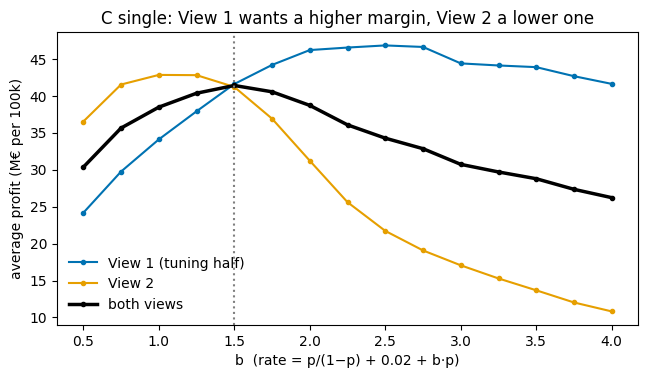

In [5]:
# C single: grid search, criterion = average of View 1 (tuning half) and View 2
A_GRID, B_GRID = [0.0, 0.01, 0.02], np.round(np.arange(0.5, 4.01, 0.25), 2)
c_grid = pd.DataFrame([{"a": a, "b": b,
                        "View 1 (tuning half)": np.mean(list(v1_scores(c_rule(p, a, b), TUNE).values())),
                        "View 2": np.mean([v2_profit(c_rule(P3, a, b), s) for s in V2_NAMES])}
                       for a in A_GRID for b in B_GRID])
c_grid["both views"] = c_grid[["View 1 (tuning half)", "View 2"]].mean(axis=1)
best_c = c_grid.loc[c_grid["both views"].idxmax()]
A_BEST, B_BEST = float(best_c.a), float(best_c.b)

# C by bucket: one b per PD quartile (loans are independent, so each bucket is tuned separately), then smoothed
edges = np.quantile(p[TUNE], np.linspace(0, 1, 5))
bucket_of = np.clip(np.searchsorted(edges, p, side="right") - 1, 0, 3)
centres = np.array([np.median(p[TUNE][bucket_of[TUNE] == k]) for k in range(4)])
bucket_b = []
for k in range(4):
    rows = TUNE[bucket_of[TUNE] == k]
    avg = {b: np.mean(list(v1_scores(c_rule(p, 0.0, b), rows).values())) for b in np.arange(0, 5.01, 0.25)}
    bucket_b.append(max(avg, key=avg.get))
bucket_b = np.array(bucket_b)

# Best response: for 100 PD levels, best rate against the real offers of similar tuning-half borrowers
MARGINS = np.concatenate([np.linspace(0, 0.10, 41), np.linspace(0.10, 1.0, 46)[1:]])
tune_rank = pd.Series(p[TUNE]).rank(pct=True).to_numpy()
levels_q = np.linspace(0.005, 0.995, 100)
levels_p = np.quantile(p[TUNE], levels_q)
br_rates = np.full(len(levels_q), np.nan)
for i, (q, lp) in enumerate(zip(levels_q, levels_p)):
    rows = TUNE[np.abs(tune_rank - q) <= 0.03]
    cand = (break_even(lp) + MARGINS)
    cand = cand[cand <= 1][:, None]
    ev = np.mean([loan_profit(cand, c1[rows][None, :], c2[rows][None, :], D[rows][None, :]).mean(axis=1)
                  for c1, c2 in V1_SCENARIOS.values()], axis=0)
    if ev.max() > 0:
        br_rates[i] = cand[int(np.argmax(ev)), 0]
br_rates = pd.Series(br_rates).rolling(5, center=True, min_periods=1).median().to_numpy()

RULES = {
    "Round 1 rule": lambda prob: c_rule(prob, 0.01, 0.75),
    "C single": lambda prob: c_rule(prob, A_BEST, B_BEST),
    "C by bucket": lambda prob: finalize(break_even(prob) + np.interp(prob, centres, bucket_b) * prob, prob),
    "Best response": lambda prob: finalize(np.interp(prob, levels_p, br_rates), prob),
}
print(f"C single: a = {A_BEST:g}, b = {B_BEST:g}")
print("C by bucket: b = " + ", ".join(f"{b:g} (PD {edges[k]:.1%}–{edges[k + 1]:.1%})" for k, b in enumerate(bucket_b)))
print(f"Best response: median rate offered {np.nanmedian(RULES['Best response'](p)):.0%}")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
curve = c_grid[c_grid["a"] == A_BEST]
for col, color in [("View 1 (tuning half)", COLORS[0]), ("View 2", COLORS[1]), ("both views", "black")]:
    ax.plot(curve["b"], curve[col], "o-", ms=3, color=color, lw=2.5 if col == "both views" else 1.5, label=col)
ax.axvline(B_BEST, color="grey", ls=":")
ax.set(xlabel=f"b  (rate = p/(1−p) + {A_BEST:g} + b·p)", ylabel="average profit (M€ per 100k)",
       title="C single: View 1 wants a higher margin, View 2 a lower one")
ax.legend(frameon=False)
plt.show()

### What rate does each rule offer?

The grey band is where rivals' Round 1 offers lay (25th–75th percentile, by PD).

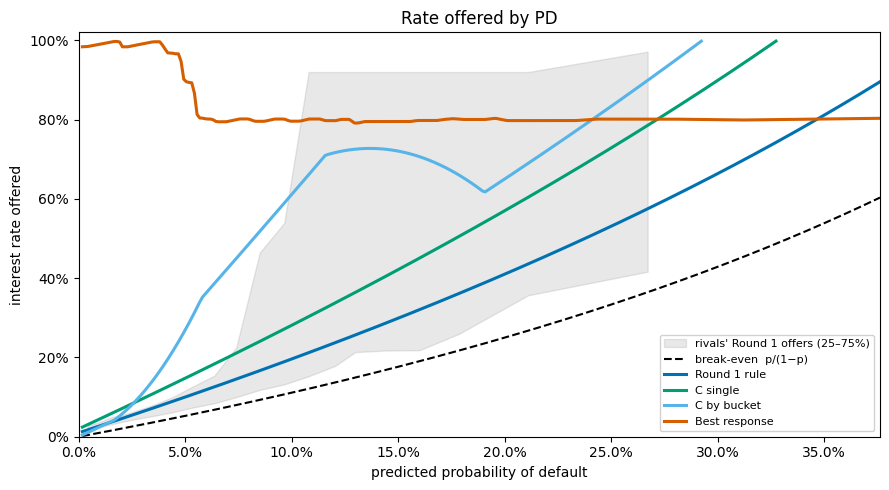

In [6]:
grid_p = np.linspace(np.quantile(p, 0.005), np.quantile(p, 0.995), 300)
all_p, all_c = np.r_[p, p], np.r_[C1, C2]
ok = ~np.isnan(all_c)
band = (pd.DataFrame({"p": all_p[ok], "c": all_c[ok]}).groupby(pd.qcut(all_p[ok], 20), observed=True)
        .agg(p=("p", "median"), lo=("c", lambda s: s.quantile(0.25)), hi=("c", lambda s: s.quantile(0.75))))
fig, ax = plt.subplots(figsize=(9, 5))
ax.fill_between(band["p"], band["lo"], band["hi"], color="grey", alpha=0.18, label="rivals' Round 1 offers (25–75%)")
ax.plot(grid_p, break_even(grid_p), "k--", lw=1.5, label="break-even  p/(1−p)")
for color, (name, rule) in zip([COLORS[0], COLORS[2], COLORS[4], COLORS[5]], RULES.items()):
    ax.plot(grid_p, rule(grid_p), color=color, lw=2.2, label=name)
ax.set(xlabel="predicted probability of default", ylabel="interest rate offered", ylim=(0, 1.02), xlim=(0, grid_p.max()),
       title="Rate offered by PD")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(frameon=True, framealpha=0.9, fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

## 5. Results

### 5a. Decision table: both views

M€ per 100,000 applicants. View 1 on the **test half** (never used for tuning); View 2 on the past-loan market.

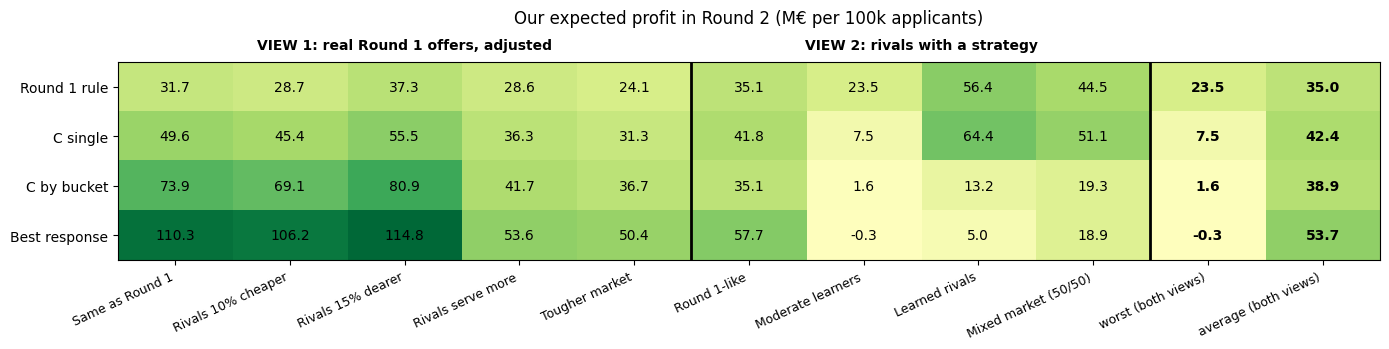

In [7]:
results = pd.DataFrame({
    name: {**{("View 1", s): v for s, v in v1_scores(rule(p), TEST).items()},
           **{("View 2", s): v2_profit(rule(P3), s) for s in V2_NAMES}}
    for name, rule in RULES.items()}).T
results.columns = pd.MultiIndex.from_tuples(results.columns)
summary = pd.DataFrame({
    "View 1 average": results["View 1"].mean(axis=1),
    "View 2 average": results["View 2"].mean(axis=1),
    "worst (both views)": results.min(axis=1),
})
summary["average (both views)"] = summary[["View 1 average", "View 2 average"]].mean(axis=1)

table = pd.concat([results["View 1"], results["View 2"], summary[["worst (both views)", "average (both views)"]]], axis=1)
vals = table.to_numpy()
fig, ax = plt.subplots(figsize=(14, 3.6))
ax.imshow(vals, cmap="RdYlGn", vmin=-vals.max(), vmax=vals.max(), aspect="auto")
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        ax.text(j, i, f"{vals[i, j]:.1f}", ha="center", va="center", fontsize=10,
                fontweight="bold" if j >= vals.shape[1] - 2 else "normal")
for xpos in [len(V1_NAMES) - 0.5, len(V1_NAMES) + len(V2_NAMES) - 0.5]:
    ax.axvline(xpos, color="black", lw=2)
ax.set_xticks(range(vals.shape[1]), table.columns, rotation=25, ha="right", fontsize=9)
ax.set_yticks(range(vals.shape[0]), table.index, fontsize=10)
ax.text((len(V1_NAMES) - 1) / 2, -0.75, "VIEW 1: real Round 1 offers, adjusted", ha="center", fontsize=10, fontweight="bold")
ax.text(len(V1_NAMES) + (len(V2_NAMES) - 1) / 2, -0.75, "VIEW 2: rivals with a strategy", ha="center", fontsize=10,
        fontweight="bold")
ax.set_title("Our expected profit in Round 2 (M€ per 100k applicants)", fontsize=12, pad=28)
plt.tight_layout()
plt.show()

### 5b. Upside vs robustness

One point per rule. **Right** = earns more if the market looks like Round 1 (View 1 average). **Up** = earns more if rivals learn (View 2 average). The best rule is the one furthest **up and to the right**; a point far right but low is a bet that rivals will not change.

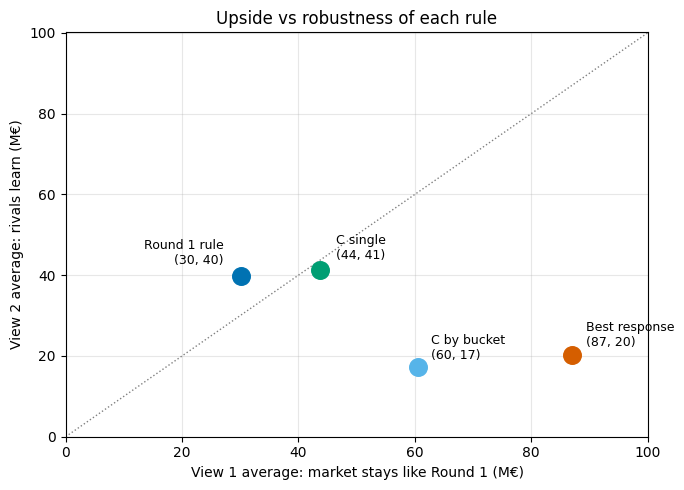

In the 'Same as Round 1' scenario:


,View 1 average,View 2 average,worst (both views),average (both views),loans won (per 100k),default on loans won,avg rate on loans won
Round 1 rule,30.1,39.9,23.5,35.0,"49,074",12.2%,22.8%
C single,43.7,41.2,7.5,42.4,"32,416",13.8%,35.6%
C by bucket,60.5,17.3,1.6,38.9,"28,817",11.7%,45.3%
Best response,87.1,20.3,-0.3,53.7,"21,115",16.4%,81.8%


In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
for color, name in zip([COLORS[0], COLORS[2], COLORS[4], COLORS[5]], RULES):
    xv, yv = summary.loc[name, "View 1 average"], summary.loc[name, "View 2 average"]
    ax.scatter(xv, yv, s=160, color=color, zorder=3)
    offset, align = {"Round 1 rule": ((-12, 8), "right"), "C single": ((12, 8), "left")}.get(name, ((10, 6), "left"))
    ax.annotate(f"{name}\n({xv:.0f}, {yv:.0f})", (xv, yv), textcoords="offset points", xytext=offset, ha=align, fontsize=9)
lim = max(summary[["View 1 average", "View 2 average"]].max()) * 1.15
ax.plot([0, lim], [0, lim], color="grey", ls=":", lw=1)
ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="View 1 average: market stays like Round 1 (M€)",
       ylabel="View 2 average: rivals learn (M€)", title="Upside vs robustness of each rule")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

volume = {}
for name, rule in RULES.items():
    rate = rule(p)[TEST]
    w = win_share(rate, C1[TEST], C2[TEST])
    volume[name] = {"loans won (per 100k)": w.sum() * N_APPLICANTS / len(TEST),
                    "default on loans won": (w * D[TEST]).sum() / w.sum(),
                    "avg rate on loans won": (w * np.nan_to_num(rate)).sum() / w.sum()}
print("In the 'Same as Round 1' scenario:")
pd.concat([summary, pd.DataFrame(volume).T], axis=1).style.format(
    {"View 1 average": "{:.1f}", "View 2 average": "{:.1f}", "worst (both views)": "{:.1f}", "average (both views)": "{:.1f}",
     "loans won (per 100k)": "{:,.0f}", "default on loans won": "{:.1%}", "avg rate on loans won": "{:.1%}"})

### 5c. Checks that did not change the decision

**Extra margin for segments with the strongest adverse selection** (`signal3 = 0`, students; see the Round 1 diagnostic) on top of C single. Tuned on the tuning half, scored on the test half and View 2.

In [9]:
r1_seg = r1[["id"]].merge(pd.read_csv(RAW_DIR / "NewApplications_Lender3_Round1.csv")[["id", "signal3", "employment"]],
                          on="id", how="left", validate="one_to_one")


def segments(frame):
    return {"s3zero": (frame["signal3"] == 0).to_numpy(), "student": (frame["employment"] == "student").to_numpy()}


def with_addons(rate, prob, seg, z_s3=0.0, z_student=0.0):
    return finalize(rate + z_s3 * seg["s3zero"] + z_student * seg["student"], prob)


SEG_V1, SEG_V2 = segments(r1_seg), segments(t30)
Z = [0.0, 0.01, 0.02, 0.03, 0.05, 0.08]
tune_avg = {(zs, zt): np.mean(list(v1_scores(with_addons(RULES["C single"](p), p, SEG_V1, zs, zt), TUNE).values()))
            for zs in Z for zt in Z}
options = {"no add-on": (0.0, 0.0),
           "signal3 = 0 only": max([k for k in tune_avg if k[1] == 0], key=tune_avg.get),
           "students only": max([k for k in tune_avg if k[0] == 0], key=tune_avg.get),
           "both": max(tune_avg, key=tune_avg.get)}
addon = {}
for label, (zs, zt) in options.items():
    v1 = v1_scores(with_addons(RULES["C single"](p), p, SEG_V1, zs, zt), TEST)
    v2 = {s: v2_profit(with_addons(RULES["C single"](P3), P3, SEG_V2, zs, zt), s) for s in V2_NAMES}
    addon[f"{label} (+{zs:.0%} signal3=0, +{zt:.0%} student)"] = {
        "View 1 average": np.mean(list(v1.values())), "View 2 average": np.mean(list(v2.values()))}
addon = pd.DataFrame(addon).T
addon["average (both views)"] = addon.mean(axis=1)
addon["vs no add-on"] = addon["average (both views)"] - addon["average (both views)"].iloc[0]
addon.round(2)

,View 1 average,View 2 average,average (both views),vs no add-on
"no add-on (+0% signal3=0, +0% student)",43.66,41.20,42.43,0.00
"signal3 = 0 only (+8% signal3=0, +0% student)",45.19,38.05,41.62,-0.81
"students only (+0% signal3=0, +8% student)",45.49,38.35,41.92,-0.51
"both (+8% signal3=0, +8% student)",47.05,35.14,41.10,-1.33


## 6. Round 2 offers

**Team decision:** `CHOSEN` is one of the four rules. Round 2 PDs come from the CatBoost refit on 200,000 loans (past loans + Round 1); its PD distribution is checked against the Stage 1 model's, since the rules depend on PD.

In [10]:
CHOSEN = "C single"  # TEAM DECISION: "Round 1 rule", "C single", "C by bucket" or "Best response"

r2_apps = pd.read_csv(RAW_DIR / "NewApplications_Lender3_Round2.csv")
r2 = r2_apps[["id"]].merge(pd.read_csv(PROCESSED_DIR / "round2_p_default_catboost_200k.csv"),
                           on="id", how="left", validate="one_to_one")
assert len(r2) == N_APPLICANTS and r2["pd"].notna().all()
qs = [0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
print("PD quantiles, Round 1 (Stage 1 model) vs Round 2 (200k model):")
print(pd.DataFrame({"Round 1": np.quantile(p, qs), "Round 2": np.quantile(r2["pd"], qs)}, index=qs).round(4).T)

offers = pd.DataFrame({"id": r2["id"], "rate": np.round(RULES[CHOSEN](r2["pd"].to_numpy()), 6)})
assert len(offers) == N_APPLICANTS and offers["id"].is_unique and set(offers["id"]) == set(r2_apps["id"])
assert offers["rate"].dropna().between(0, 1, inclusive="right").all()
offers.to_csv(PROCESSED_DIR / "stage2_offers_lender3.csv", index=False)
print(f"\nChosen rule: {CHOSEN}")
print(f"Saved stage2_offers_lender3.csv: {len(offers):,} rows | offers {offers['rate'].notna().mean():.1%} | "
      f"mean rate {offers['rate'].mean():.1%} | median {offers['rate'].median():.1%}")

PD quantiles, Round 1 (Stage 1 model) vs Round 2 (200k model):
           0.05    0.25    0.50    0.75    0.95    0.99
Round 1  0.0067  0.0343  0.0867  0.1461  0.2349  0.3376
Round 2  0.0071  0.0358  0.0874  0.1452  0.2407  0.3162

Chosen rule: C single
Saved stage2_offers_lender3.csv: 100,000 rows | offers 99.2% | mean rate 28.0% | median 24.4%
